Welcome to Visualization...

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [74]:
df = pd.read_csv("../data/laptops_cleaned.csv", encoding="latin-1")

In [75]:
df.head(2)

,Laptop,Status,Brand,Model,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,ASUS ExpertBook B1 B1502CBA-EJ0436X Intel Core...,New,Asus,ExpertBook,Intel Core i5,8,512,SSD,Integrated,15.6,No,1009.0
1,Alurin Go Start Intel Celeron N4020/8GB/256GB ...,New,Alurin,Go,Intel Celeron,8,256,SSD,Integrated,15.6,No,299.0


In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2159 entries, 0 to 2158
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Laptop        2159 non-null   str    
 1   Status        2159 non-null   str    
 2   Brand         2159 non-null   str    
 3   Model         2159 non-null   str    
 4   CPU           2159 non-null   str    
 5   RAM           2159 non-null   int64  
 6   Storage       2159 non-null   int64  
 7   Storage type  2159 non-null   str    
 8   GPU           2159 non-null   str    
 9   Screen        2159 non-null   float64
 10  Touch         2159 non-null   str    
 11  Final Price   2159 non-null   float64
dtypes: float64(2), int64(2), str(8)
memory usage: 202.5 KB


In [77]:
df.columns

Index(['Laptop', 'Status', 'Brand', 'Model', 'CPU', 'RAM', 'Storage',
       'Storage type', 'GPU', 'Screen', 'Touch', 'Final Price'],
      dtype='str')

<Axes: xlabel='Final Price', ylabel='Count'>

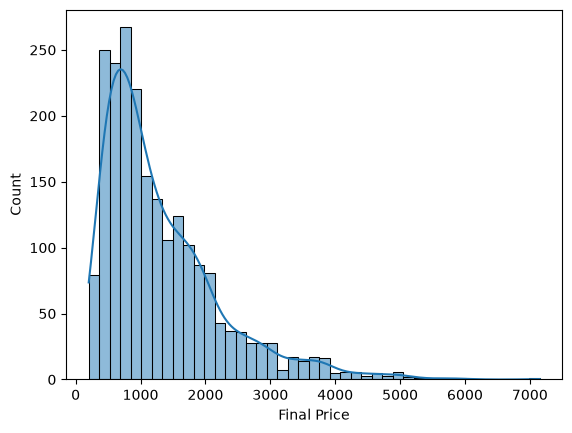

In [78]:
sns.histplot(data=df, x=df["Final Price"], kde=True)

<Axes: xlabel='Final Price'>

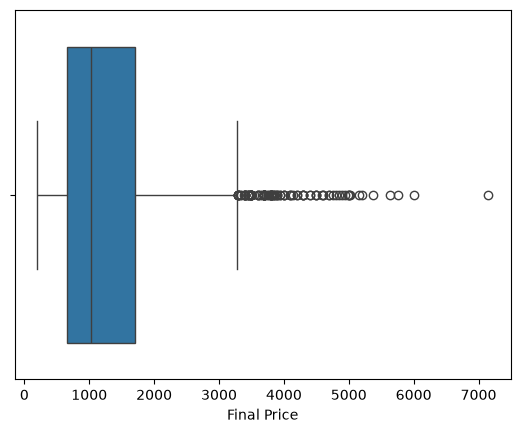

In [79]:
sns.boxplot(data=df, x=df["Final Price"])

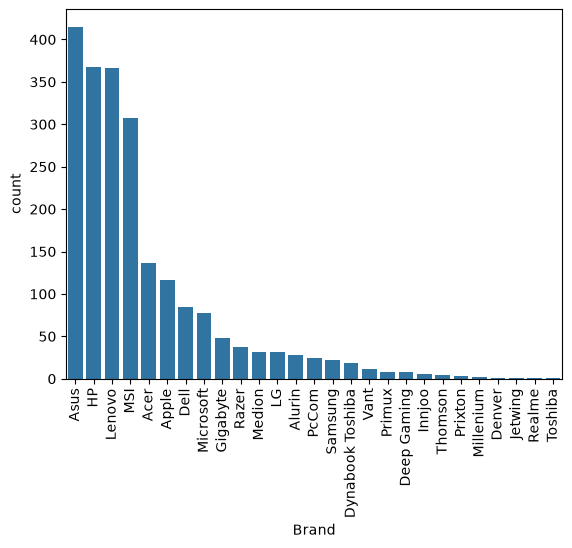

In [80]:
sns.countplot(data=df, x="Brand", order=df["Brand"].value_counts().index)
plt.xticks(rotation = 90)
plt.show()

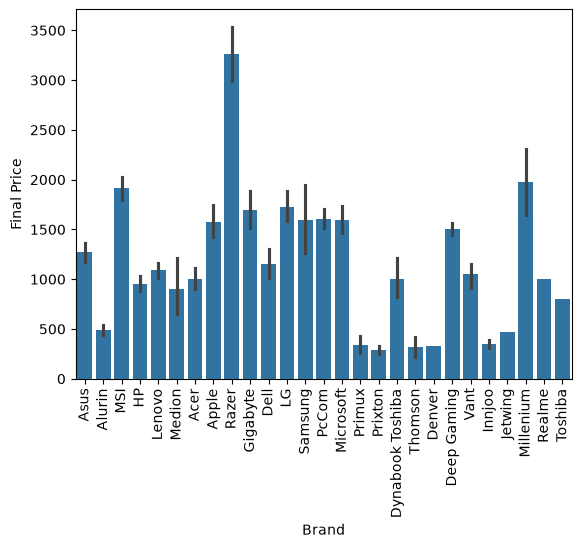

In [81]:
sns.barplot(data=df, x="Brand", y="Final Price", estimator="mean")
plt.xticks(rotation = 90)
plt.show()

<Axes: xlabel='Status', ylabel='Final Price'>

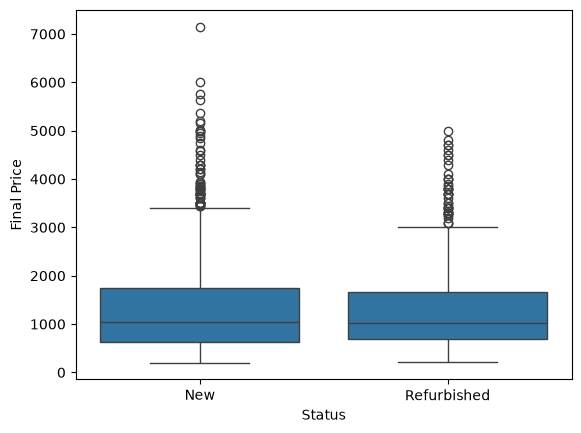

In [82]:
sns.boxplot(data=df, x=df["Status"], y=df["Final Price"])

<Axes: xlabel='Touch', ylabel='Final Price'>

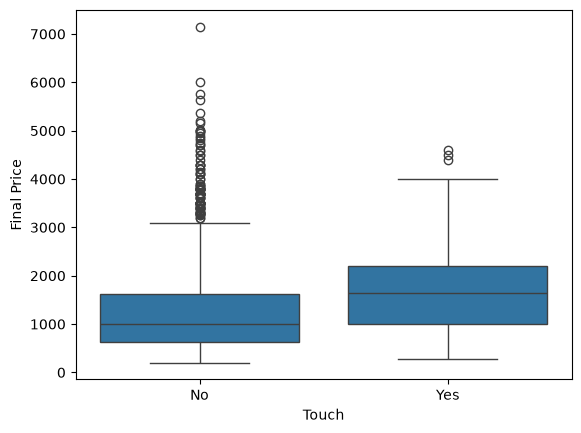

In [83]:
sns.boxplot(data=df, x=df["Touch"], y=df["Final Price"])

<Axes: xlabel='RAM', ylabel='Final Price'>

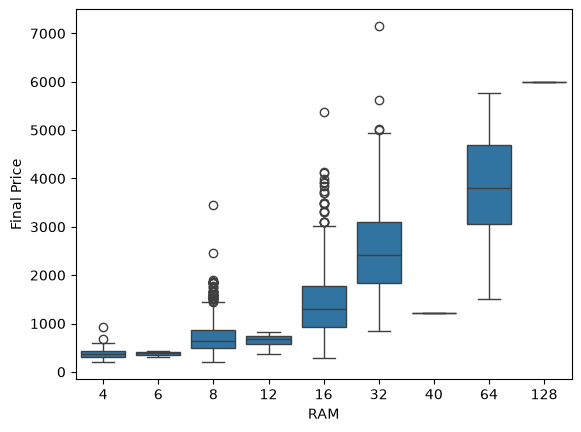

In [84]:
sns.boxplot(data=df, x=df["RAM"], y=df["Final Price"])

<Axes: xlabel='Storage', ylabel='Final Price'>

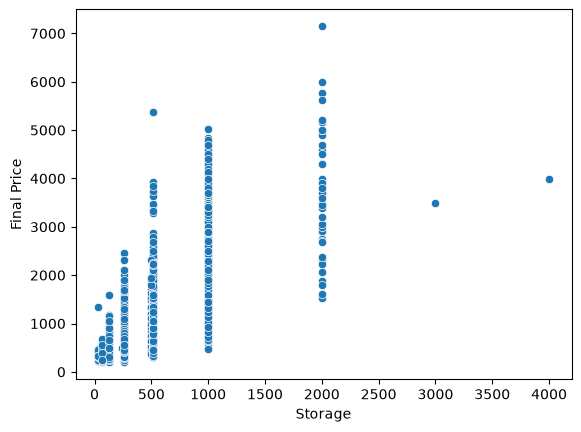

In [85]:
sns.scatterplot(df, x=df["Storage"], y=df["Final Price"])

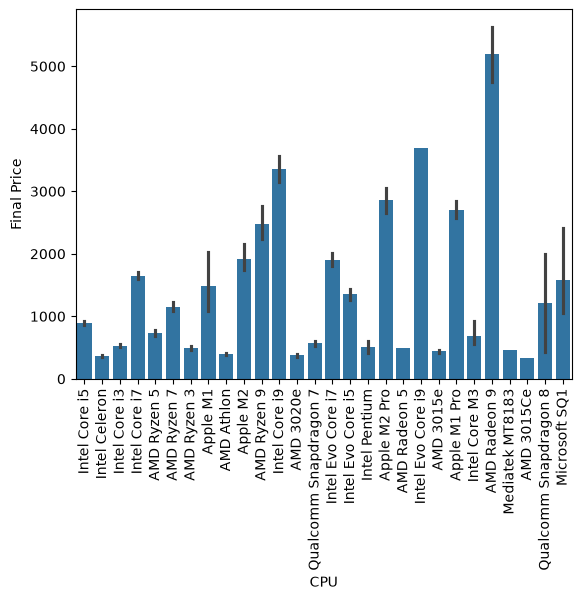

In [86]:
sns.barplot(data=df, x="CPU", y="Final Price", estimator="mean")
plt.xticks(rotation = 90)
plt.show()

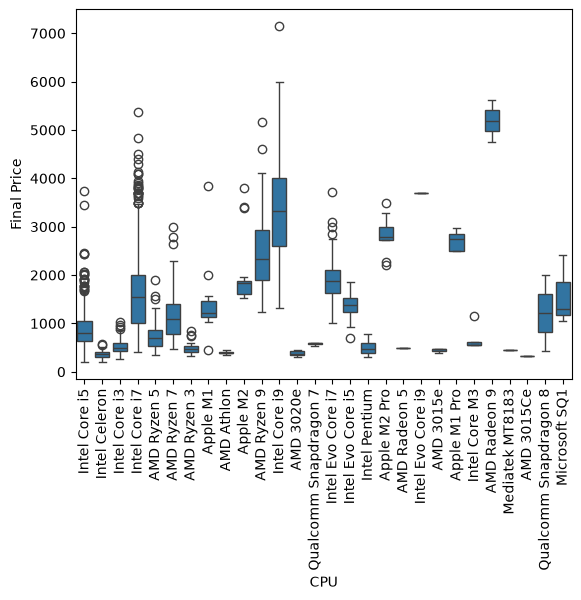

In [87]:
sns.boxplot(df, x="CPU", y="Final Price")
plt.xticks(rotation = 90)
plt.show()

<Axes: xlabel='Screen', ylabel='Final Price'>

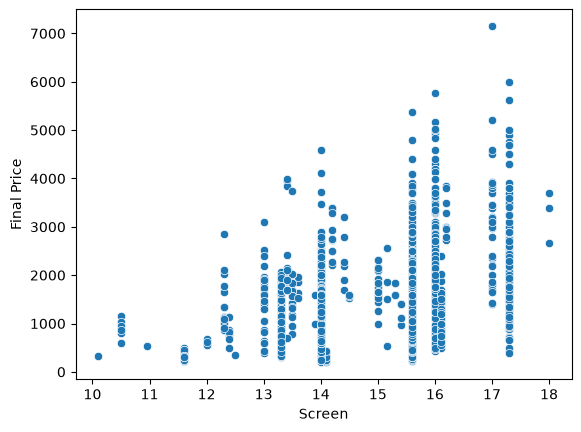

In [88]:
sns.scatterplot(df, x="Screen", y="Final Price")

<Axes: >

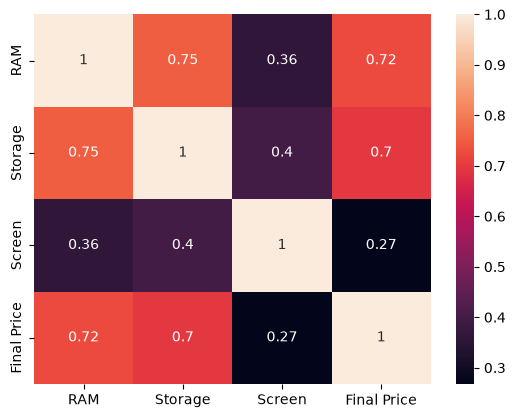

In [89]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True)

## Feature Engineering

In [90]:
df["Brand"].value_counts()

Brand
Asus                415
HP                  368
Lenovo              366
MSI                 308
Acer                137
Apple               116
Dell                 84
Microsoft            77
Gigabyte             48
Razer                37
Medion               32
LG                   32
Alurin               28
PcCom                24
Samsung              22
Dynabook Toshiba     19
Vant                 11
Primux                8
Deep Gaming           8
Innjoo                6
Thomson               4
Prixton               3
Millenium             2
Denver                1
Jetwing               1
Realme                1
Toshiba               1
Name: count, dtype: int64

In [91]:
brand_counts = df["Brand"].value_counts()

def brand_count(brand):
    if brand_counts[brand] > 30:
        return brand
    else:
        return "Other"

df["Brand"] = df["Brand"].apply(brand_count)

In [92]:
df["CPU"].value_counts()

CPU
Intel Core i7            710
Intel Core i5            534
AMD Ryzen 7              156
Intel Core i3            130
AMD Ryzen 5              127
Intel Celeron             94
Intel Core i9             94
Intel Evo Core i7         82
AMD Ryzen 3               44
AMD Ryzen 9               44
Intel Evo Core i5         30
Apple M2                  28
AMD 3020e                 13
Apple M2 Pro              13
Apple M1                  11
AMD Athlon                10
Intel Pentium             10
Apple M1 Pro               7
Intel Core M3              5
Qualcomm Snapdragon 7      3
AMD 3015e                  3
Microsoft SQ1              3
AMD Radeon 9               2
Qualcomm Snapdragon 8      2
AMD Radeon 5               1
Intel Evo Core i9          1
Mediatek MT8183            1
AMD 3015Ce                 1
Name: count, dtype: int64

In [93]:
CPU_counts = df["CPU"].value_counts()

def CPU_count(CPU):
    if CPU_counts[CPU] > 30:
        return CPU
    else:
        return "Other"

df["CPU"] = df["CPU"].apply(CPU_count)

In [94]:
GPU_counts = df["GPU"].value_counts()

def GPU_count(GPU):
    if GPU_counts.get(GPU, 0) > 30:
        return GPU
    else:
        return "Other"

df["GPU"] = df["GPU"].apply(GPU_count)

In [95]:
df.drop(columns=["Laptop", "Model"], inplace=True)

C:\Users\PC\AppData\Local\Temp\ipykernel_5996\791614756.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Laptop", "Model"], inplace=True)


In [96]:
df.head()

,Status,Brand,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price
0,New,Asus,Intel Core i5,8,512,SSD,Integrated,15.6,No,1009.00
1,New,Other,Intel Celeron,8,256,SSD,Integrated,15.6,No,299.00
2,New,Asus,Intel Core i3,8,256,SSD,Integrated,15.6,No,789.00
3,New,MSI,Intel Core i7,16,1000,SSD,RTX 3050,15.6,No,1199.00
4,New,HP,Intel Core i5,16,512,SSD,Integrated,15.6,No,669.01


### Log Price convert

In [97]:

df["Log_Price"] = np.log1p(df["Final Price"])

In [98]:
# y_pred_price = np.expm1(6) # after model test if we need real price then ue this


In [99]:
df.head()

,Status,Brand,CPU,RAM,Storage,Storage type,GPU,Screen,Touch,Final Price,Log_Price
0,New,Asus,Intel Core i5,8,512,SSD,Integrated,15.6,No,1009.00,6.917706
1,New,Other,Intel Celeron,8,256,SSD,Integrated,15.6,No,299.00,5.703782
2,New,Asus,Intel Core i3,8,256,SSD,Integrated,15.6,No,789.00,6.672033
3,New,MSI,Intel Core i7,16,1000,SSD,RTX 3050,15.6,No,1199.00,7.090077
4,New,HP,Intel Core i5,16,512,SSD,Integrated,15.6,No,669.01,6.507293


## Train Test Split

In [100]:
X = df.drop(columns=["Final Price", "Log_Price"])
y = df["Log_Price"]

In [101]:
Cetegorical = ["Status", "Brand", "CPU", "Storage type", "GPU", "Touch"]
Numeric = ["RAM", "Storage", "Screen"]

In [102]:
X_Encoded = pd.get_dummies(data=X, columns=Cetegorical, drop_first=True, dtype=int)

In [103]:
X_Encoded.head()

,RAM,Storage,Screen,Status_Refurbished,Brand_Apple,Brand_Asus,Brand_Dell,Brand_Gigabyte,Brand_HP,Brand_LG,...,GPU_Integrated,GPU_Other,GPU_RTX 3050,GPU_RTX 3060,GPU_RTX 3070,GPU_RTX 3080,GPU_RTX 4050,GPU_RTX 4060,GPU_RTX 4070,Touch_Yes
0,8,512,15.6,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1,8,256,15.6,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,8,256,15.6,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,16,1000,15.6,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,16,512,15.6,0,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0


X_Encoded ----- input -- one hot encode - need standerdscaler
y ----------output

In [104]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_Encoded, y, test_size=0.20, random_state=42)

## model

In [105]:
from sklearn.linear_model import LinearRegression

Model_LinReg = LinearRegression()
Model_LinReg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](37,)","[ 0.02, 0. ,-0.01,..., 0.35, 0.41, 0.28]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](37,)","['RAM','Storage','Screen',...,'GPU_RTX 4060','GPU_RTX 4070','Touch_Yes']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.085
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,37
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(37)


In [106]:
y_pred = Model_LinReg.predict(X_test)

## Performence Checkk

In [107]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [108]:
# ERROR finder

y_pred_price = np.expm1(y_pred)
y_test_price = np.expm1(y_test)

print("MAE:", mean_absolute_error(y_test_price, y_pred_price))

print("MSE:", mean_squared_error(y_test_price, y_pred_price))

print("RMSE:", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))
print("R2:", r2_score(y_test_price, y_pred_price))

MAE: 316.52981482703007
MSE: 280731.33982821746
RMSE: 529.8408627391979
R2: 0.6625081693541339


## Ridge 

In [109]:
from sklearn.linear_model import Ridge
Model_RigReg = Ridge()
Model_RigReg.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [110]:
y_pred_ridg = Model_RigReg.predict(X_test)

In [111]:
y_pred_price = np.expm1(y_pred_ridg)
y_test_price = np.expm1(y_test)

print("MAE:", mean_absolute_error(y_test_price, y_pred_price))

print("MSE:", mean_squared_error(y_test_price, y_pred_price))

print("RMSE:", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))
print("R2:", r2_score(y_test_price, y_pred_price))

MAE: 318.30999080277184
MSE: 285245.5668280463
RMSE: 534.0838574868616
R2: 0.657081220104166


## Lasso

In [112]:
from sklearn.linear_model import Lasso
Model_Lasso = Lasso()
Model_Lasso.fit(X_train, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [113]:
y_pred_Lasso = Model_Lasso.predict(X_test)

In [114]:
y_pred_price = np.expm1(y_pred_Lasso)
y_test_price = np.expm1(y_test)

print("MAE:", mean_absolute_error(y_test_price, y_pred_price))

print("MSE:", mean_squared_error(y_test_price, y_pred_price))

print("RMSE:", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))
print("R2:", r2_score(y_test_price, y_pred_price))

MAE: 505.15194117551033
MSE: 607897.8495960116
RMSE: 779.6780422687377
R2: 0.26919253749373595


## Random Forest

In [115]:
from sklearn.ensemble import  RandomForestRegressor
Model_RenFor = RandomForestRegressor()
Model_RenFor.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [116]:
y_pred_RenFor = Model_RenFor.predict(X_test)

In [117]:
y_pred_price = np.expm1(y_pred_RenFor)
y_test_price = np.expm1(y_test)

print("MAE:", mean_absolute_error(y_test_price, y_pred_price))

print("MSE:", mean_squared_error(y_test_price, y_pred_price))

print("RMSE:", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))
print("R2:", r2_score(y_test_price, y_pred_price))

MAE: 246.11269591629684
MSE: 176093.08988212075
RMSE: 419.6344717514527
R2: 0.7883030113247427


## Gradient Boosting

In [118]:
from sklearn.ensemble import GradientBoostingRegressor
Model_GreBtg = GradientBoostingRegressor()
Model_GreBtg.fit(X_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init in

In [119]:
y_pred_GreBtg = Model_GreBtg.predict(X_test)

In [120]:
y_pred_price = np.expm1(y_pred_GreBtg)
y_test_price = np.expm1(y_test)

print("MAE:", mean_absolute_error(y_test_price, y_pred_price))

print("MSE:", mean_squared_error(y_test_price, y_pred_price))

print("RMSE:", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))
print("R2:", r2_score(y_test_price, y_pred_price))

MAE: 276.4834585869238
MSE: 188539.29833155585
RMSE: 434.2111218423082
R2: 0.7733403296491941


## XGB

In [121]:
import xgboost
Model_XGB = xgboost.XGBRegressor()
Model_XGB.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [122]:
y_pred_XGB = Model_XGB.predict(X_test)

In [123]:
y_pred_price = np.expm1(y_pred_XGB)
y_test_price = np.expm1(y_test)

print("MAE:", mean_absolute_error(y_test_price, y_pred_price))

print("MSE:", mean_squared_error(y_test_price, y_pred_price))

print("RMSE:", np.sqrt(mean_squared_error(y_test_price, y_pred_price)))
print("R2:", r2_score(y_test_price, y_pred_price))

MAE: 244.1180965833311
MSE: 173251.93767405493
RMSE: 416.23543538970216
R2: 0.7917186102401699


Crossvalidation Check (XGB, RF, GB)

In [124]:
from sklearn.model_selection import cross_val_score, KFold


In [125]:
scores = cross_val_score(
    Model_XGB,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("5-Fold Scores:", scores)
print("Mean Score:", scores.mean())
print("Standerd Score:", scores.std())

print("Train R2:", Model_XGB.score(X_train, y_train))
print("Test R2:", Model_XGB.score(X_test, y_test))

5-Fold Scores: [0.85751962 0.83932207 0.8282839  0.84826821 0.80338369]
Mean Score: 0.8353554981479778
Standerd Score: 0.018686486594983485
Train R2: 0.9285467525292301
Test R2: 0.8329300386049454


## RendomizedSearchCV

In [126]:
from sklearn.model_selection import RandomizedSearchCV

params = {
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.07, 0.1],
    "n_estimators": [300, 500, 700, 1000],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7, 10],
    "reg_lambda": [1, 3, 5, 10, 20],
    "reg_alpha": [0, 0.1, 0.5, 1, 5, 10]
}

random_search = RandomizedSearchCV(
    estimator=Model_XGB,
    param_distributions=params,
    n_iter=50,
    scoring="r2",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV R2:", random_search.best_score_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'subsample': 0.6, 'reg_lambda': 3, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.07, 'colsample_bytree': 0.7}
Best CV R2: 0.8469020753124935


In [127]:
# XGB Model  
Best_XGB = random_search.best_estimator_
print("Train R2:", Best_XGB.score(X_train, y_train))
print("Test R2:", Best_XGB.score(X_test, y_test))

Train R2: 0.9067928853379219
Test R2: 0.8356821727267407


In [128]:
y_pred_BestXGB = Best_XGB.predict(X_test)

y_pred_euro = np.expm1(y_pred_BestXGB)
y_test_euro = np.expm1(y_test)

mae = mean_absolute_error(y_test_euro, y_pred_euro)
rmse = np.sqrt(mean_squared_error(y_test_euro, y_pred_euro))

# 1 prediction me MAE jitna upar niche ho sakta haii
print(f"Tuned XGB MAE: €{mae:.2f}")
print(f"Tuned XGB RMSE: €{rmse:.2f}")

Tuned XGB MAE: €241.94
Tuned XGB RMSE: €406.95


In [129]:
importance = Best_XGB.feature_importances_

feature_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})


top_15 = feature_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

top_15

,Feature,Importance
0,RAM,0.170023
19,CPU_Intel Celeron,0.110131
23,CPU_Intel Core i9,0.069087
24,CPU_Intel Evo Core i7,0.054014
27,GPU_Integrated,0.053054
1,Storage,0.042079
4,Brand_Apple,0.039196
18,CPU_AMD Ryzen 9,0.034603
15,Brand_Razer,0.033757
22,CPU_Intel Core i7,0.032300


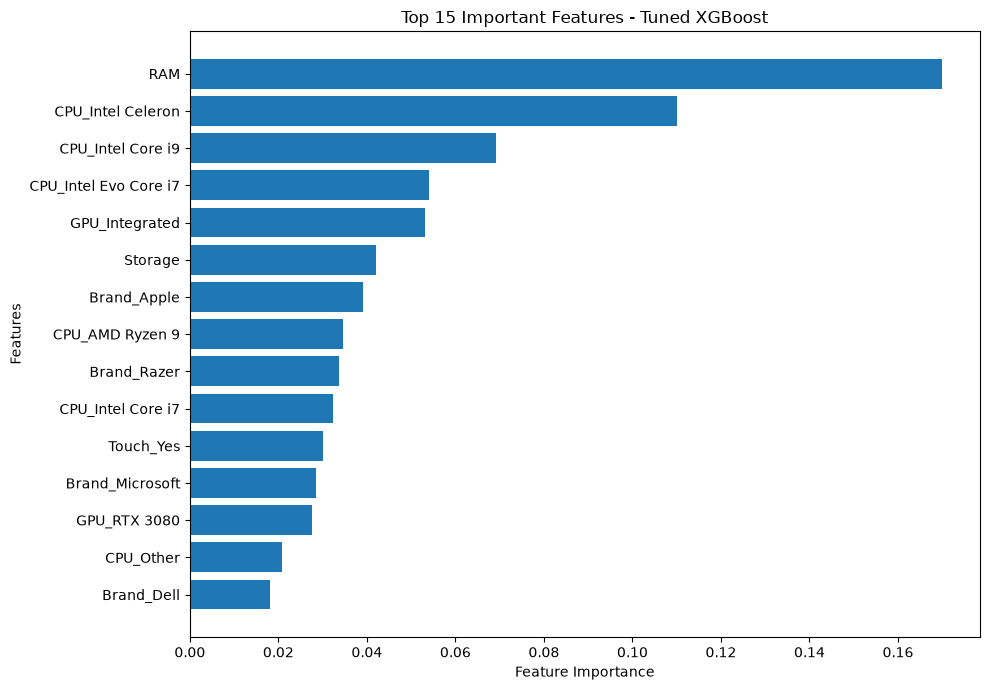

In [130]:
plt.figure(figsize=(10, 7))

plt.barh(top_15["Feature"], top_15["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Tuned XGBoost")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Actual VS Predicted

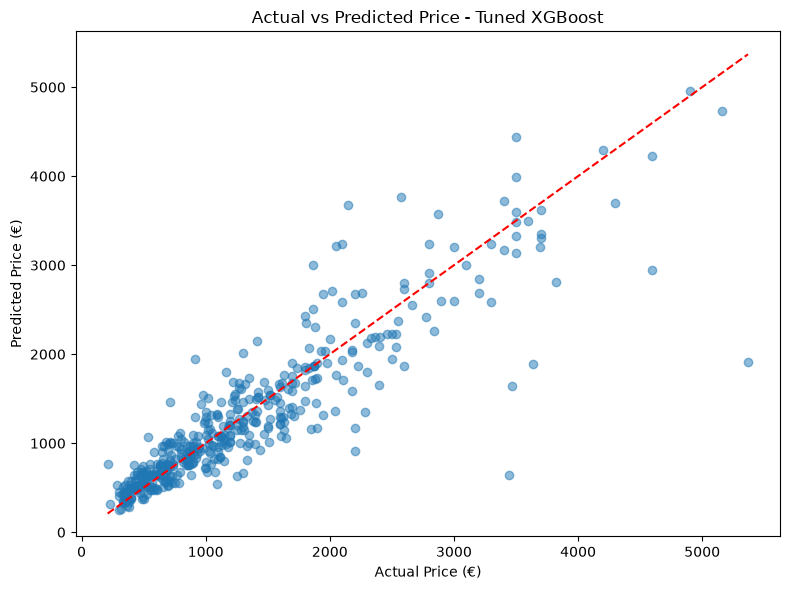

In [131]:

# Convert to Euro
y_pred_euro = np.expm1(Best_XGB.predict(X_test))
y_test_euro = np.expm1(y_test)

# Scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(y_test_euro, y_pred_euro, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test_euro.min(), y_test_euro.max()],
    [y_test_euro.min(), y_test_euro.max()],
    "r--"
)

plt.xlabel("Actual Price (€)")
plt.ylabel("Predicted Price (€)")
plt.title("Actual vs Predicted Price - Tuned XGBoost")

plt.tight_layout()
plt.show()

## Save Model

In [132]:
import os
import joblib
import json

# os.makedirs("model", exist_ok=True)

joblib.dump(Best_XGB, "../model/tuned_xgb_model.pkl")

feature_columns = X_train.columns.tolist()

with open("../model/feature_columns.json", "w") as f:
    json.dump(feature_columns, f)



========== INPUT COMPARISON ==========
Total features: 37
Mismatched features: 0
All features match!

========== PREDICTION COMPARISON ==========
Notebook prediction: € 1462.83
Saved model on notebook input: € 1462.83
Saved model on Streamlit input: € 1462.83
